# EDA 10: bằng chứng để gộp khoảng trống (gap) vào home/office

Tiếp nối `08_gap_stay.ipynb` và `09_home_office_windows.ipynb`. Stay dùng `h1_keep`. Notebook này hỏi: khi tính home/office, **gap có đáng tin không và nên xử lý thế nào**.

**Đáp án để chấm.** Home/office suy ra chỉ từ **giờ có GPS** (`home_gps`: nơi nhiều giờ GPS đêm 0–6h nhất; `office_gps`: nơi nhiều giờ GPS thứ 2–6, 9–17h nhất). Chỉ dùng user có đủ giờ GPS ở nơi đó (`MIN_GPS_NIGHT_H`, `MIN_GPS_OFFICE_H`). **Hạn chế:** GPS ban đêm là lúc máy bật, thường là lúc đang thức hoặc đang đi, nên đáp án GPS là **tham chiếu**, không phải sự thật. Khi gap và GPS không khớp, chưa chắc gap sai.

| Mục | Câu hỏi | Trình bày |
|---|---|---|
| 27 | Gap chiếm bao nhiêu giờ đêm và giờ hành chính? Home/office phụ thuộc gap đến mức nào? | bảng 27, hình |
| 28 | Gap qua đêm / ban ngày có thật sự nằm ở home / office (đáp án GPS) không, theo độ dài và khoảng cách hai đầu? | bảng 28a–28c, hình |
| 29 | Bao nhiêu đêm / ngày làm việc là đủ để bỏ phiếu (A11)? | bảng, hình |

**Cách chạy.** `run_compare` (stay `h1_keep`) đọc từ cache của notebook 07, nếu chưa có thì tự tính vài phút. `run_evidence` vài phút; lưu từng user ở `data/interim/eda_stay_anchor/<user>_gapev.pkl`; đổi code `gap_evidence.py` thì xoá các file đó.


In [22]:
# chạy được ngay cả khi chưa chạy các mục trước
import importlib
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from preprocess import interim
from eda import stay_anchor as sa
from eda import gap_evidence as ge
from eda import stay_anchor_plots as sp
from eda import split
for m in (sa, ge, sp):
    importlib.reload(m)

USERS = None              # ví dụ ["000", "001", "002"] để chạy thử nhanh
MIN_GPS_NIGHT_H = 10      # giờ GPS đêm tối thiểu ở nơi đó để tin làm đáp án home
MIN_GPS_OFFICE_H = 20     # giờ GPS hành chính tối thiểu ở nơi đó để tin làm đáp án office

users = split.dev_users()
if USERS:
    users = [u for u in users if u in set(USERS)]
sa.run_compare(users)                       # stay h1_keep; đọc từ cache nếu đã chạy notebook 07
U, G, H = ge.run_evidence(users)

home_ok = U["home_gps_hours"] >= MIN_GPS_NIGHT_H
office_ok = U["office_gps_hours"] >= MIN_GPS_OFFICE_H
G = G.merge(U[["user"]].assign(home_ok=home_ok.to_numpy(), office_ok=office_ok.to_numpy()), on="user")
G.loc[~G["home_ok"], "d_home"] = np.nan
G.loc[~G["office_ok"], "d_office"] = np.nan
print(f"{len(U)} user; đủ GPS để làm đáp án: home {home_ok.sum()}, office {office_ok.sum()}, cả hai {(home_ok & office_ok).sum()}")
print(f"{len(G):,} khoảng trống > 30 phút nằm trong stay")

122 user đã có kết quả, 0 user cần tính, 15 tiến trình
122 user đã có kết quả, 0 user cần tính, 15 tiến trình
114 user; đủ GPS để làm đáp án: home 14, office 6, cả hai 4
9,217 khoảng trống > 30 phút nằm trong stay


## 27. Gap chiếm bao nhiêu giờ đêm và giờ hành chính

Với mỗi giờ trong ngày, bao nhiêu % thời gian là gap (máy không ghi > 30 phút). Rồi theo từng user: % giờ đêm và giờ hành chính là gap, và phần giờ của home / office (tính như Li hiện nay, cộng mọi gap) đến từ gap.

Nếu phần này gần 100% thì home/office của user gần như hoàn toàn dựa vào gap, nên cách xử lý gap quyết định kết quả.

Bảng 27. Phần của gap trong giờ đêm / giờ hành chính, theo user


,số user,p10,trung vị,p90
% giờ đêm (0–6h) là gap,114.0,94.3,99.2,100.0
% giờ hành chính là gap,109.0,82.3,96.0,99.5
% giờ đêm của nơi home (đếm mọi gap) đến từ gap,97.0,30.8,98.8,100.0
% giờ hành chính của nơi office (đếm mọi gap) đến từ gap,103.0,36.4,97.0,99.8


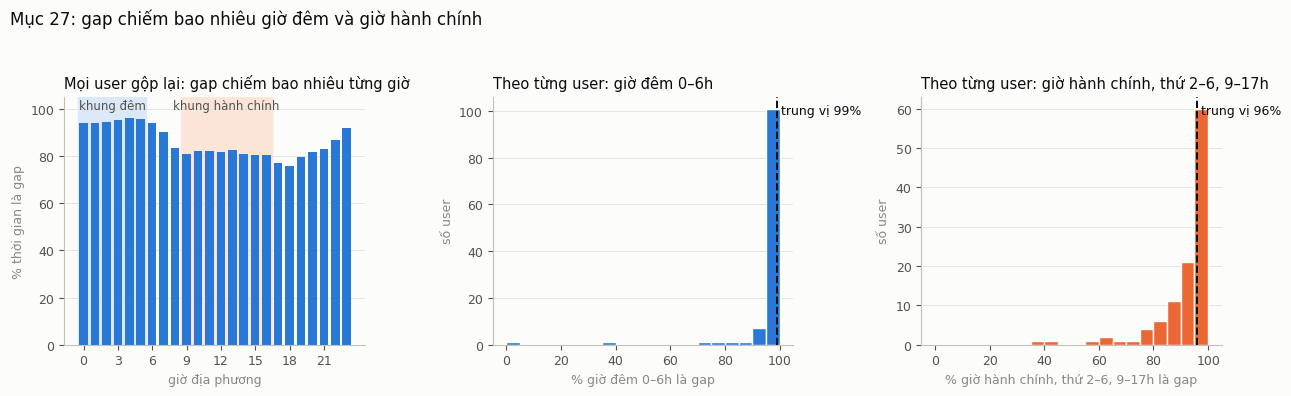

In [23]:
def phan_vi(s):
    s = s.dropna()
    return pd.Series({"số user": len(s), "p10": s.quantile(0.1), "trung vị": s.median(), "p90": s.quantile(0.9)})

bang1 = pd.DataFrame({
    "% giờ đêm (0–6h) là gap": phan_vi(100 * U["night_gap_h"] / (U["night_gap_h"] + U["night_gps_h"])),
    "% giờ hành chính là gap": phan_vi(100 * U["office_gap_h"] / (U["office_gap_h"] + U["office_gps_h"])),
    "% giờ đêm của nơi home (đếm mọi gap) đến từ gap": phan_vi(100 * U["home_gap_share"]),
    "% giờ hành chính của nơi office (đếm mọi gap) đến từ gap": phan_vi(100 * U["office_gap_share"]),
}).T
print("Bảng 27. Phần của gap trong giờ đêm / giờ hành chính, theo user")
display(bang1.round(1))
sp.gap_coverage(H, U);

## 28. Gap có ở home / office không

Với mỗi khoảng trống trong stay, lấy **hai đầu** (điểm ngay trước và ngay sau) và đo xa nhất trong hai đầu cách `home_gps` / `office_gps` bao nhiêu. "Ở nơi đó" = cả hai đầu cách tâm địa điểm ≤ 300 m (200 m bán kính stay + dư cho nhiễu GPS). Chỉ tính user đủ GPS làm đáp án.

- **28a.** Gap qua đêm, hai đầu gần nhau : bao nhiêu % ở home, theo độ dài.
- **28b.** Gap qua đêm, theo hai đầu cách nhau bao xa: hai đầu xa nhau có còn ở home không.
- **28c.** Gap ban ngày, hai đầu gần nhau: % ở office và % ở home (WFH), theo độ dài.

Mốc để coi là đáng tin: ≥ 90% ở nơi đó và đủ mẫu (cột `n`).

Bảng 28a. Gap qua đêm, hai đầu gần nhau: % ở HOME (cả hai đầu cách home ≤ 300 m)


,n,pct_ở_nơi_đó,trung_vị_m
độ dài (giờ),,,
"(2.0, 4.0]",3,66.7,17.7
"(4.0, 8.0]",15,53.3,226.3
"(8.0, 12.0]",213,68.1,137.4
"(12.0, 24.0]",259,58.7,169.2


Bảng 28b. Gap qua đêm, theo hai đầu cách nhau: % ở HOME


,n,pct_ở_nơi_đó,trung_vị_m
hai đầu cách nhau (m),,,
"(0.0, 200.0]",489,62.6,152.2
"(200.0, 400.0]",139,59.0,266.9


Bảng 28c. Gap ban ngày, hai đầu gần nhau: % ở OFFICE (trên) và % ở HOME (dưới)


,n,pct_ở_nơi_đó,trung_vị_m
độ dài (giờ),,,
"(0.5, 1.0]",644,23.1,7932.5
"(1.0, 2.0]",444,23.0,6772.5
"(2.0, 4.0]",222,23.4,4860.7
"(4.0, 8.0]",113,53.1,277.7
"(8.0, 12.0]",94,79.8,171.8
"(12.0, 24.0]",164,28.0,3014.2


,n,pct_ở_nơi_đó,trung_vị_m
độ dài (giờ),,,
"(0.5, 1.0]",840,19.2,8008.5
"(1.0, 2.0]",622,16.7,6786.4
"(2.0, 4.0]",408,12.7,6718.2
"(4.0, 8.0]",170,17.1,3700.7
"(8.0, 12.0]",350,3.7,3718.7
"(12.0, 24.0]",346,48.0,1321.9


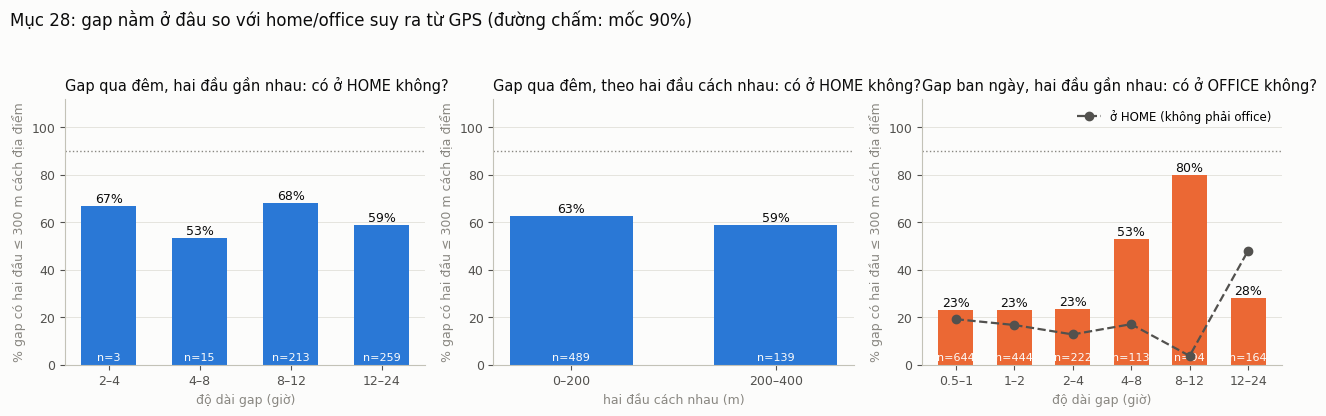

In [24]:
gan = G["end_m"] <= ge.NEAR_M
dem = G["overnight"]
ngay = ~G["overnight"]

b2a = ge.at_place_by_length(G, "home", dem & gan)
b2b = ge.at_place_by_ends(G, "home", dem)
b2c_off = ge.at_place_by_length(G, "office", ngay & gan)
b2c_home = ge.at_place_by_length(G, "home", ngay & gan)
print("Bảng 28a. Gap qua đêm, hai đầu gần nhau: % ở HOME (cả hai đầu cách home ≤ 300 m)")
display(b2a.round(1))
print("Bảng 28b. Gap qua đêm, theo hai đầu cách nhau: % ở HOME")
display(b2b.round(1))
print("Bảng 28c. Gap ban ngày, hai đầu gần nhau: % ở OFFICE (trên) và % ở HOME (dưới)")
display(b2c_off.round(1)); display(b2c_home.round(1))
sp.gap_agreement(b2a, b2b, b2c_off, b2c_home);

## 29. Bao nhiêu đêm / ngày làm việc là đủ để bỏ phiếu (A11)

**Câu hỏi:** bỏ phiếu home / office (D18, `places/home_office_conf.py`) cần ít nhất bao nhiêu đêm / ngày làm việc có phiếu thì kết quả mới lặp lại được?

**Cách đo (hai mẫu rời nhau):** với mỗi user và mỗi k, bốc ngẫu nhiên 2k phiếu từ các đêm (home) hoặc ngày làm việc (office) có phiếu, chia hai nhóm rời nhau mỗi nhóm k phiếu, bỏ phiếu riêng từng nhóm, rồi hỏi **hai nhóm có cho cùng nơi thắng không**. Lặp 200 lần, lấy trung bình theo user rồi theo nhóm user. Không có "chuẩn" trùng với mẫu, và chỉ cần user có ít nhất 2k phiếu (k = 7 cần 14 phiếu, không phải 30).

**Cách đọc mức tin cậy:** nếu mỗi nhóm trùng nơi thắng thật với xác suất q thì hai nhóm trùng nhau khoảng q². Mức 81% hai nhóm trùng nhau ứng với mỗi nhóm trùng chuẩn khoảng 90%. Mức 90% là quy ước.

**Hạn chế:** đo độ **tái lập**, không đo độ đúng, vì chưa có đáp án (A13). Khi k tăng thì số user có đủ 2k phiếu giảm và nhóm user thay đổi, nên đường "mọi user" có thể tăng vì đổi nhóm user. Vì vậy vẽ thêm **nhóm cố định** (user có ít nhất 28 phiếu, dùng được mọi k đến 14). User có hai nơi sát nhau (kể cả do gom địa điểm v1 cắt đôi một nơi) sẽ không bao giờ trùng nhau dù có nhiều phiếu.

{'home': 114, 'office': 114} user có ít nhất 2 phiếu cho k nhỏ nhất
Phép đo này phủ bao nhiêu: user cần ít nhất t phiếu (2k phiếu cho k = t / 2); nhóm dev có 122 user


số user  % user của nhóm  % tổng số phiếu
loại   điều kiện                                            
home   ≥ 6 phiếu      62.0             50.8             96.8
       ≥ 10 phiếu     49.0             40.2             93.8
       ≥ 14 phiếu     43.0             35.2             91.7
       ≥ 20 phiếu     29.0             23.8             84.3
       ≥ 28 phiếu     25.0             20.5             81.6
office ≥ 6 phiếu      58.0             47.5             96.2
       ≥ 10 phiếu     42.0             34.4             91.4
       ≥ 14 phiếu     34.0             27.9             87.8
       ≥ 20 phiếu     25.0             20.5             81.9
       ≥ 28 phiếu     18.0             14.8             75.2

Bảng 29. % hai nhóm rời nhau cho cùng nơi thắng, theo số phiếu mỗi nhóm (mức tin cậy 81%)


,home: mọi user (%),home: số user,home: nhóm cố định (%),office: mọi user (%),office: số user,office: nhóm cố định (%)
số phiếu mỗi nhóm,,,,,,
k = 3,45.1,62.0,46.0,39.4,58.0,36.9
k = 5,56.0,49.0,61.2,46.5,42.0,49.8
k = 7,63.1,43.0,67.3,57.8,34.0,60.7
k = 10,71.8,29.0,72.9,68.8,25.0,68.6
k = 14,77.4,25.0,77.4,74.7,18.0,74.7


home, mọi user dùng được: k nhỏ nhất đạt 81% và không tụt lại = None (87 user)
home, nhóm cố định (≥ 28 phiếu): k nhỏ nhất đạt 81% và không tụt lại = None (25 user)
office, mọi user dùng được: k nhỏ nhất đạt 81% và không tụt lại = None (85 user)
office, nhóm cố định (≥ 28 phiếu): k nhỏ nhất đạt 81% và không tụt lại = None (18 user)


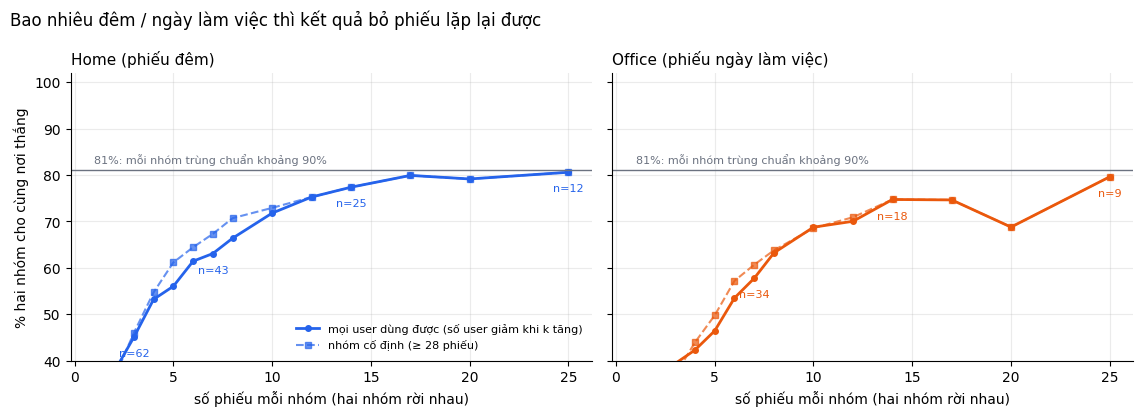

In [25]:
from eda import min_days as md
importlib.reload(md)
D29 = md.run(users)
print({k: int(D29[D29["kind"] == k]["user"].nunique()) for k in ("home", "office")}, "user có ít nhất 2 phiếu cho k nhỏ nhất")
print(f"Phép đo này phủ bao nhiêu: user cần ít nhất t phiếu (2k phiếu cho k = t / 2); nhóm dev có {len(users)} user")
display(md.coverage(D29, len(users)).round(1))
print(f"Bảng 29. % hai nhóm rời nhau cho cùng nơi thắng, theo số phiếu mỗi nhóm (mức tin cậy {100 * md.THR:.0f}%)")
display(md.table(D29).round(1))
for kind in ("home", "office"):
    for fixed in (False, True):
        k, n = md.first_k(D29, kind, fixed)
        nhom = f"nhóm cố định (≥ {md.N_FIXED} phiếu)" if fixed else "mọi user dùng được"
        print(f"{kind}, {nhom}: k nhỏ nhất đạt {100 * md.THR:.0f}% và không tụt lại = {k} ({n} user)")
md.plot(D29);

**Cần đọc ra ở mục 29 (điền sau khi chạy):**
- Đường cong lên nhanh hay chậm? Ở k = 7 hai nhóm trùng nhau bao nhiêu % (home, office), và k nhỏ nhất đạt 81%?
- Nhóm cố định và nhóm "mọi user dùng được" có cho cùng kết luận không (nếu khác thì do đổi nhóm user theo k)?
- Dựa vào đó chốt `N_MIN_NIGHTS` và `N_MIN_WORKDAYS` (hiện nháp 7) trong `home_office_conf.py` và A11, ghi rõ đây là quy ước dựa vào độ tái lập.

## Kết luận (lần chạy ngày 2026-11-05)

- Giờ đêm và giờ hành chính của phần lớn user gần như hoàn toàn là gap (mục 27), nên cách xử lý gap quyết định home/office.
- Đáp án GPS quá ít user đủ giờ để chấm (mục 28) và bản thân thiên lệch (lúc máy bật), nên chưa chứng minh được quy tắc nhận gap theo mục đích (qua đêm cho home, ban ngày ngắn cho office) là đúng hay sai. Không dùng quy tắc đó làm mặc định.
- Học giờ nghỉ từng user từ gap dài đã thử và bỏ khỏi notebook (số liệu giữ ở D14): không ổn định hơn khung cố định cùng loại, và làm home/office của một phần user đổi.
- **Cập nhật 2026-11-05:** cách chốt home/office hiện hành là D18 (khung đêm 20–7h, ngày làm việc 8:30–18h, bỏ phiếu theo số phút chồng khung, `home_office_conf.py`), thay cho giờ mốc 3h / 13h của D14. Kết luận về gap vẫn đúng với phép thử đã làm.


## 30. Confidence có dự đoán được kết quả ở giai đoạn sau không

**Câu hỏi:** user có confidence cao khi chỉ nhìn **nửa đầu** thời gian dữ liệu có giữ nguyên home / office ở **nửa sau** nhiều hơn user confidence thấp không?

**Cách đo:** chia stay của từng user thành hai nửa theo giờ đến (trung vị thời gian). Chạy bỏ phiếu (D18) riêng trên từng nửa. Confidence và vùng (thấp, giữa, cao theo tam phân vị trên chính nhóm đang xét) lấy từ **nửa đầu**. Hai kết quả "trùng" khi cùng `place_id` hoặc hai tâm cách nhau ≤ 200 m. Khác thành phần "ổn định" của confidence, thành phần đó tính từ cả hai nửa cùng lúc nên không dùng để kiểm ở đây.

**Giới hạn:** đo độ **tái lập theo thời gian**, không đo độ đúng (không có đáp án, A13). User ở yên một nơi sẽ trùng dù confidence thấp vì dữ liệu ít. Mỗi nửa chỉ còn khoảng một nửa số phiếu nên nửa sau cũng thiếu dữ liệu; chỉ so trong số user có kết quả ở cả hai nửa (cột `có kết quả nửa sau` cho biết bao nhiêu). Chỉ nhóm dev; nhóm test để dành.

In [26]:
from eda import conf_holdout as ch
importlib.reload(ch)
R30 = ch.run(split.dev_users())
for kind in ("home", "office"):
    g, rho, n_both = ch.summary(R30, kind)
    print(f"Bảng 30 ({kind}): confidence nửa đầu và việc giữ nguyên nơi ở nửa sau. {n_both} user có kết quả ở cả hai nửa")
    display(g.round(2))
    print(f"Tương quan hạng giữa confidence nửa đầu và trùng nơi: {rho:.2f}\n")

Bảng 30 (home): confidence nửa đầu và việc giữ nguyên nơi ở nửa sau. 85 user có kết quả ở cả hai nửa


,user có kết quả nửa đầu,có kết quả nửa sau,trùng nơi (% trong số có cả hai),"conf nửa đầu, trung bình"
vùng (nửa đầu),,,,
thấp,22,21,42.86,0.03
giữa,36,33,42.42,0.24
cao,31,31,74.19,0.58


Tương quan hạng giữa confidence nửa đầu và trùng nơi: 0.25

Bảng 30 (office): confidence nửa đầu và việc giữ nguyên nơi ở nửa sau. 44 user có kết quả ở cả hai nửa


,user có kết quả nửa đầu,có kết quả nửa sau,trùng nơi (% trong số có cả hai),"conf nửa đầu, trung bình"
vùng (nửa đầu),,,,
thấp,19,14,7.14,0.08
giữa,17,14,57.14,0.24
cao,20,16,75.00,0.58


Tương quan hạng giữa confidence nửa đầu và trùng nơi: 0.59



**Đọc kết quả** (số ở bảng trên): nếu tỉ lệ trùng tăng từ vùng thấp lên vùng cao và tương quan hạng dương rõ thì confidence có ý nghĩa dự đoán độ tái lập. Nếu ba vùng gần như bằng nhau hoặc tương quan gần 0 thì confidence chưa phân biệt được user chắc và không chắc. Mẫu mỗi vùng chỉ vài chục user nên chênh vài điểm phần trăm chưa đáng tin; chỉ đọc các chênh lệch lớn.

### 30.1 Theo số phiếu thật ở nửa đầu

Cùng phép chia nửa đầu / nửa sau, nhưng nhóm theo **số phiếu thật của user ở nửa đầu** (1–3, 4–6, 7–13, từ 14) thay vì theo vùng confidence. Mỗi nhóm gồm đúng những user chỉ có chừng đó phiếu, nên không suy từ user nhiều phiếu sang user ít phiếu. Chỉ lấy user có ít nhất 7 phiếu ở nửa sau để nửa sau đủ làm chuẩn. **Hạn chế:** nửa sau cũng là một mẫu nên tỉ lệ trùng bị đo thấp hơn thực tế; mẫu mỗi nhóm nhỏ.

In [27]:
for kind in ("home", "office"):
    print(f"Bảng 30.1 ({kind}): nơi thắng nửa đầu có trùng nửa sau không, theo số phiếu thật ở nửa đầu (nửa sau ≥ 7 phiếu)")
    display(ch.summary_by_votes(R30, kind).round(1))

Bảng 30.1 (home): nơi thắng nửa đầu có trùng nửa sau không, theo số phiếu thật ở nửa đầu (nửa sau ≥ 7 phiếu)


,số user,trùng nơi (%)
số phiếu nửa đầu,,
1–3,0,NaN
4–6,2,50.0
7–13,10,60.0
từ 14,26,61.5


Bảng 30.1 (office): nơi thắng nửa đầu có trùng nửa sau không, theo số phiếu thật ở nửa đầu (nửa sau ≥ 7 phiếu)


,số user,trùng nơi (%)
số phiếu nửa đầu,,
1–3,0,NaN
4–6,3,66.7
7–13,6,66.7
từ 14,11,81.8


**Đọc kết quả** (số ở bảng trên): nếu tỉ lệ trùng tăng rõ khi số phiếu nửa đầu tăng thì số phiếu thật ảnh hưởng độ tái lập, và nhóm nào còn dưới mức mong muốn là nhóm chưa đủ phiếu. Nhóm có ít user thì chỉ đọc xu hướng, không đọc chênh vài điểm phần trăm.